# Task 1: Which games should an AI clipping platform support next?

**Goal:** find popular games that the platform doesn't support yet.

**How:** take the most-played games on Steam and check which ones already have a clipping AI model.

**Data:** SteamSpy (top 100 games) and the official Steam API (players online right now). Both are free and public.

In [1]:
%pip install requests pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import time
from datetime import datetime, timezone

import requests
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

STEAMSPY_URL = "https://steamspy.com/api.php"
PLAYERS_URL = "https://api.steampowered.com/ISteamUserStats/GetNumberOfCurrentPlayers/v1/"

session = requests.Session()
session.headers["User-Agent"] = "steam-coverage-analysis"
problems = []  # I keep a record of every retry or failed call

## Step 1: Make data collection reliable

Websites sometimes respond slowly or block too many requests. The `fetch()` function below tries again a few times, waits when the website asks it to, and skips a request only if it keeps failing. This way one error doesn't stop the whole process.

In [3]:
def fetch(url, params, tries=4):
    for attempt in range(1, tries + 1):
        try:
            r = session.get(url, params=params, timeout=20)
        except requests.RequestException as e:
            problems.append(f"{params}: {type(e).__name__}")
            time.sleep(2 ** attempt)
            continue

        if r.status_code == 429:
            wait = int(r.headers.get("Retry-After", 30))
            problems.append(f"{params}: rate limited, waited {wait}s")
            time.sleep(wait)
            continue

        if r.status_code >= 500:
            problems.append(f"{params}: server error {r.status_code}")
            time.sleep(2 ** attempt)
            continue

        if r.status_code != 200:
            problems.append(f"{params}: HTTP {r.status_code}, skipped")
            return None

        try:
            return r.json()
        except ValueError:
            problems.append(f"{params}: response was not valid JSON")
            time.sleep(2 ** attempt)

    problems.append(f"{params}: gave up after {tries} tries")
    return None

## Step 2: Get the top 100 games

In [4]:
collected_at = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")

top100 = fetch(STEAMSPY_URL, {"request": "top100in2weeks"})
if top100 is None:
    raise SystemExit("Couldn't get the SteamSpy list. Check your connection and run this cell again.")

raw = pd.DataFrame(top100.values())
raw.to_csv("steam_top100_raw.csv", index=False)
print(f"Got {len(raw)} games ({collected_at})")
raw[["appid", "name", "owners", "average_2weeks", "positive", "negative"]].head()

Got 100 games (2026-10-17 05:24 UTC)


,appid,name,owners,average_2weeks,positive,negative
0,730,Counter-Strike: Global Offensive,"100,000,000 .. 200,000,000",0,7642084,1173003
1,1172470,Apex Legends,"100,000,000 .. 200,000,000",0,668053,326926
2,578080,PUBG: BATTLEGROUNDS,"100,000,000 .. 200,000,000",0,1520457,1037487
3,1623730,Palworld,"50,000,000 .. 100,000,000",0,358266,22443
4,440,Team Fortress 2,"50,000,000 .. 100,000,000",0,1044264,117208


## Step 3: Check how many people are playing each game right now

This takes about 1 to 2 minutes. If a game's live number can't be loaded, a backup number from SteamSpy is used instead.

In [5]:
players_now = {}
for appid in raw["appid"]:
    data = fetch(PLAYERS_URL, {"appid": appid})
    if data and data.get("response", {}).get("result") == 1:
        players_now[appid] = data["response"]["player_count"]
    time.sleep(0.3)

raw["players_now"] = raw["appid"].map(players_now)
print(f"Live player counts: {raw['players_now'].notna().sum()} of {len(raw)} games")
print(f"Problems handled along the way: {len(problems)}")

Live player counts: 99 of 100 games
Problems handled along the way: 1


## Step 4: Clean the data

1. Remove symbols like ™ and ® from game names
2. Remove apps that aren't real games, such as Wallpaper Engine
3. Match Steam game names with the platform's list of supported games

In [6]:
df = raw.copy()

for col in ["appid", "ccu", "average_2weeks", "positive", "negative", "players_now"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["source"] = df["players_now"].notna().map({True: "Steam API", False: "SteamSpy (fallback)"})
df["players_now"] = df["players_now"].fillna(df["ccu"]).fillna(0).astype(int)

df["name"] = df["name"].astype(str).str.replace(r"[™®©]", "", regex=True).str.strip()
df = df.drop_duplicates("appid")


def midpoint(owners_text):
    nums = [int(n.replace(",", "")) for n in re.findall(r"[\d,]+", str(owners_text))]
    return sum(nums) / len(nums) if nums else None


df["owners"] = df["owners"].apply(midpoint)
df["playtime_2w_hours"] = (df["average_2weeks"] / 60).round(1)
df["positive_reviews_pct"] = (100 * df["positive"] / (df["positive"] + df["negative"])).round(1)

not_games = ["wallpaper engine", "soundpad", "lossless scaling", "steamvr", "banana", "bongo cat", "egg", "cats"]
df["is_game"] = ~df["name"].str.lower().isin(not_games)

In [7]:
# Games the platform supports (from the Task 3 data), written as keywords that appear in the Steam name
supported_games = {
    "call of duty": "COD", "fortnite": "Fortnite", "smite": "SMITE", "apex legends": "Apex Legends",
    "league of legends": "League of Legends", "world of warcraft": "World of Warcraft",
    "rocket league": "Rocket League", "rainbow six": "Rainbow Six Siege", "nba 2k": "NBA 2K",
    "dead by daylight": "Dead by Daylight", "counter-strike": "Counter Strike 2", "madden nfl": "Madden NFL",
    "ea sports fc": "EA Sports FC", "fifa": "EA Sports FC", "among us": "Among Us", "halo": "Halo Infinite",
    "fall guys": "Fall Guys", "destiny": "Destiny", "the finals": "THE FINALS", "roblox": "ROBLOX",
    "mortal kombat": "Mortal Kombat 1", "farlight": "Farlight84", "pubg": "PUBG", "starfield": "Starfield",
    "texas chain saw": "Texas Chain Saw Massacre", "party animals": "Party Animals",
    "phasmophobia": "Phasmophobia", "elden ring": "Elden Ring", "naraka": "Naraka", "lies of p": "Lies of P",
    "honkai: star rail": "Honkai: Star Rail", "street fighter": "Street Fighter",
    "my hero ultra rumble": "My Hero Ultra Rumble", "forza motorsport": "Forza Motorsport",
    "rogue company": "Rogue Company", "world of tanks": "World of Tanks", "remnant": "Remnant 2",
    "payday": "PAYDAY 3", "spider-man": "Spider-Man 2", "nhl": "NHL", "mlb the show": "MLB The Show",
    "hearthstone": "Hearthstone", "battlebit": "BattleBit", "yu-gi-oh": "Yu-Gi-Oh! Master Duel",
    "battlefield": "Battlefield",
}


def find_model(name):
    for keyword, model in supported_games.items():
        if keyword in name.lower():
            return model
    return None


df["model_name"] = df["name"].apply(find_model)
df["supported"] = df["model_name"].notna()
df = df.sort_values("players_now", ascending=False).reset_index(drop=True)

df[["appid", "name", "is_game", "supported", "model_name", "players_now", "source",
    "owners", "playtime_2w_hours", "positive_reviews_pct"]].to_csv("steam_games_clean.csv", index=False)
df[["name", "players_now", "supported", "model_name"]].head(10)

,name,players_now,supported,model_name
0,Counter-Strike: Global Offensive,572386,True,Counter Strike 2
1,PUBG: BATTLEGROUNDS,323013,True,PUBG
2,Apex Legends,104501,True,Apex Legends
3,Wallpaper Engine,83419,False,NaN
4,Call of Duty: Modern Warfare II,81391,True,COD
5,Warframe,75776,False,NaN
6,Team Fortress 2,69706,False,NaN
7,Valheim,69640,False,NaN
8,Rust,64637,False,NaN
9,Tom Clancy's Rainbow Six Siege,61706,True,Rainbow Six Siege


## Step 5: How many players does the platform cover?

*Note: Steam only includes PC games sold on Steam, so games like Fortnite and VALORANT are not counted here.*

In [8]:
games = df[df["is_game"]]
total = games["players_now"].sum()
covered = games.loc[games["supported"], "players_now"].sum()

print(f"People playing the top {len(games)} Steam games right now: {total:,}")
print(f"...of which are in a game the platform supports: {covered:,} ({covered / total:.1%})")
print(f"Supported games in the top list: {games['supported'].sum()} of {len(games)}")

People playing the top 99 Steam games right now: 2,652,501
...of which are in a game the platform supports: 1,347,765 (50.8%)
Supported games in the top list: 24 of 99


In [9]:
# Same calculation for the top 20 only (the games shown in the chart below)
top20_all = games.head(20)
t20_total = top20_all["players_now"].sum()
t20_covered = top20_all.loc[top20_all["supported"], "players_now"].sum()
print(f"Top 20: {t20_covered:,} of {t20_total:,} players are in a supported game ({t20_covered / t20_total:.1%})")
print(f"Supported games in the top 20: {top20_all['supported'].sum()} of 20")

# How much of that comes from the single biggest game?
biggest = top20_all.iloc[0]
rest = top20_all.iloc[1:]
rest_cov = rest.loc[rest["supported"], "players_now"].sum() / rest["players_now"].sum()
print(f"Without {biggest['name']}: {rest_cov:.1%}")

Top 20: 1,188,520 of 1,911,225 players are in a supported game (62.2%)
Supported games in the top 20: 6 of 20
Without Counter-Strike: Global Offensive: 46.0%


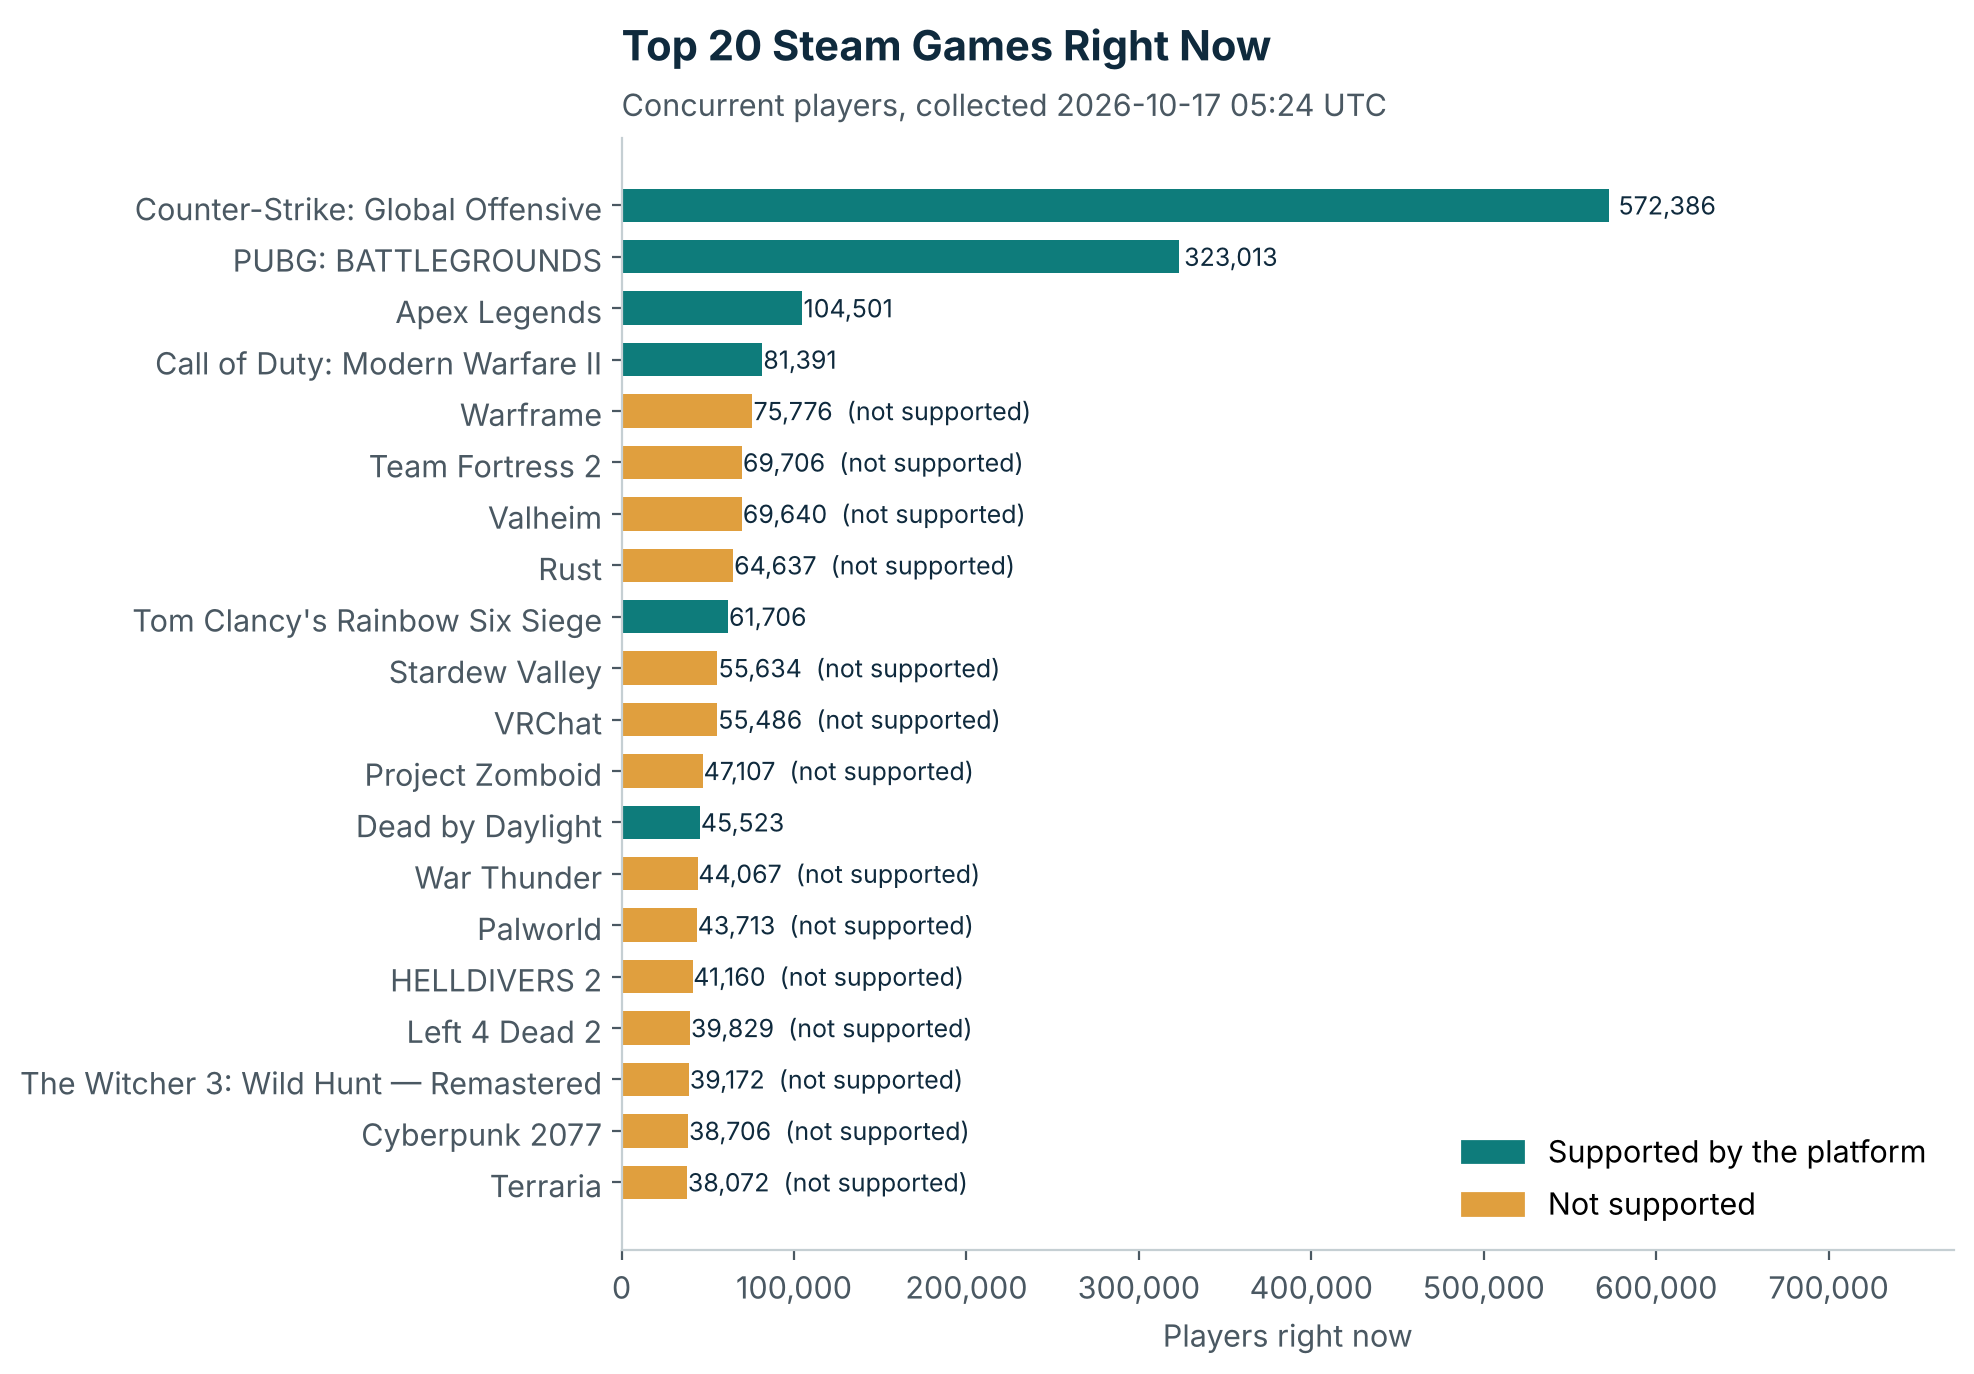

In [10]:
TEAL, AMBER, GRAY, INK, SLATE = "#0e7c7b", "#e09f3e", "#c5cfd3", "#0f2a3d", "#4a5862"
plt.rcParams.update({
    "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRAY, "axes.labelcolor": SLATE,
    "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.spines.top": False, "axes.spines.right": False,
})

top20 = games.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top20["name"], top20["players_now"], height=0.65,
        color=[TEAL if s else AMBER for s in top20["supported"]])
for i, (players, supported) in enumerate(zip(top20["players_now"], top20["supported"])):
    label = f"{players:,}" if supported else f"{players:,}  (not supported)"
    ax.text(players * 1.01, i, label, va="center", fontsize=9, color=INK)

ax.set_xlim(0, top20["players_now"].max() * 1.35)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Players right now")
ax.legend(handles=[Patch(color=TEAL, label="Supported by the platform"), Patch(color=AMBER, label="Not supported")],
          frameon=False, loc="lower right")
ax.set_title("Top 20 Steam Games Right Now", loc="left", fontsize=15, fontweight="bold", color=INK, pad=28)
ax.text(0, 1.02, f"Concurrent players, collected {collected_at}", transform=ax.transAxes, fontsize=11, color=SLATE)
fig.tight_layout()
fig.savefig("task1_top20_games.png", dpi=200)
plt.show()

## Step 6: Which games should the platform add next?

The biggest games on Steam that the platform doesn't support yet.

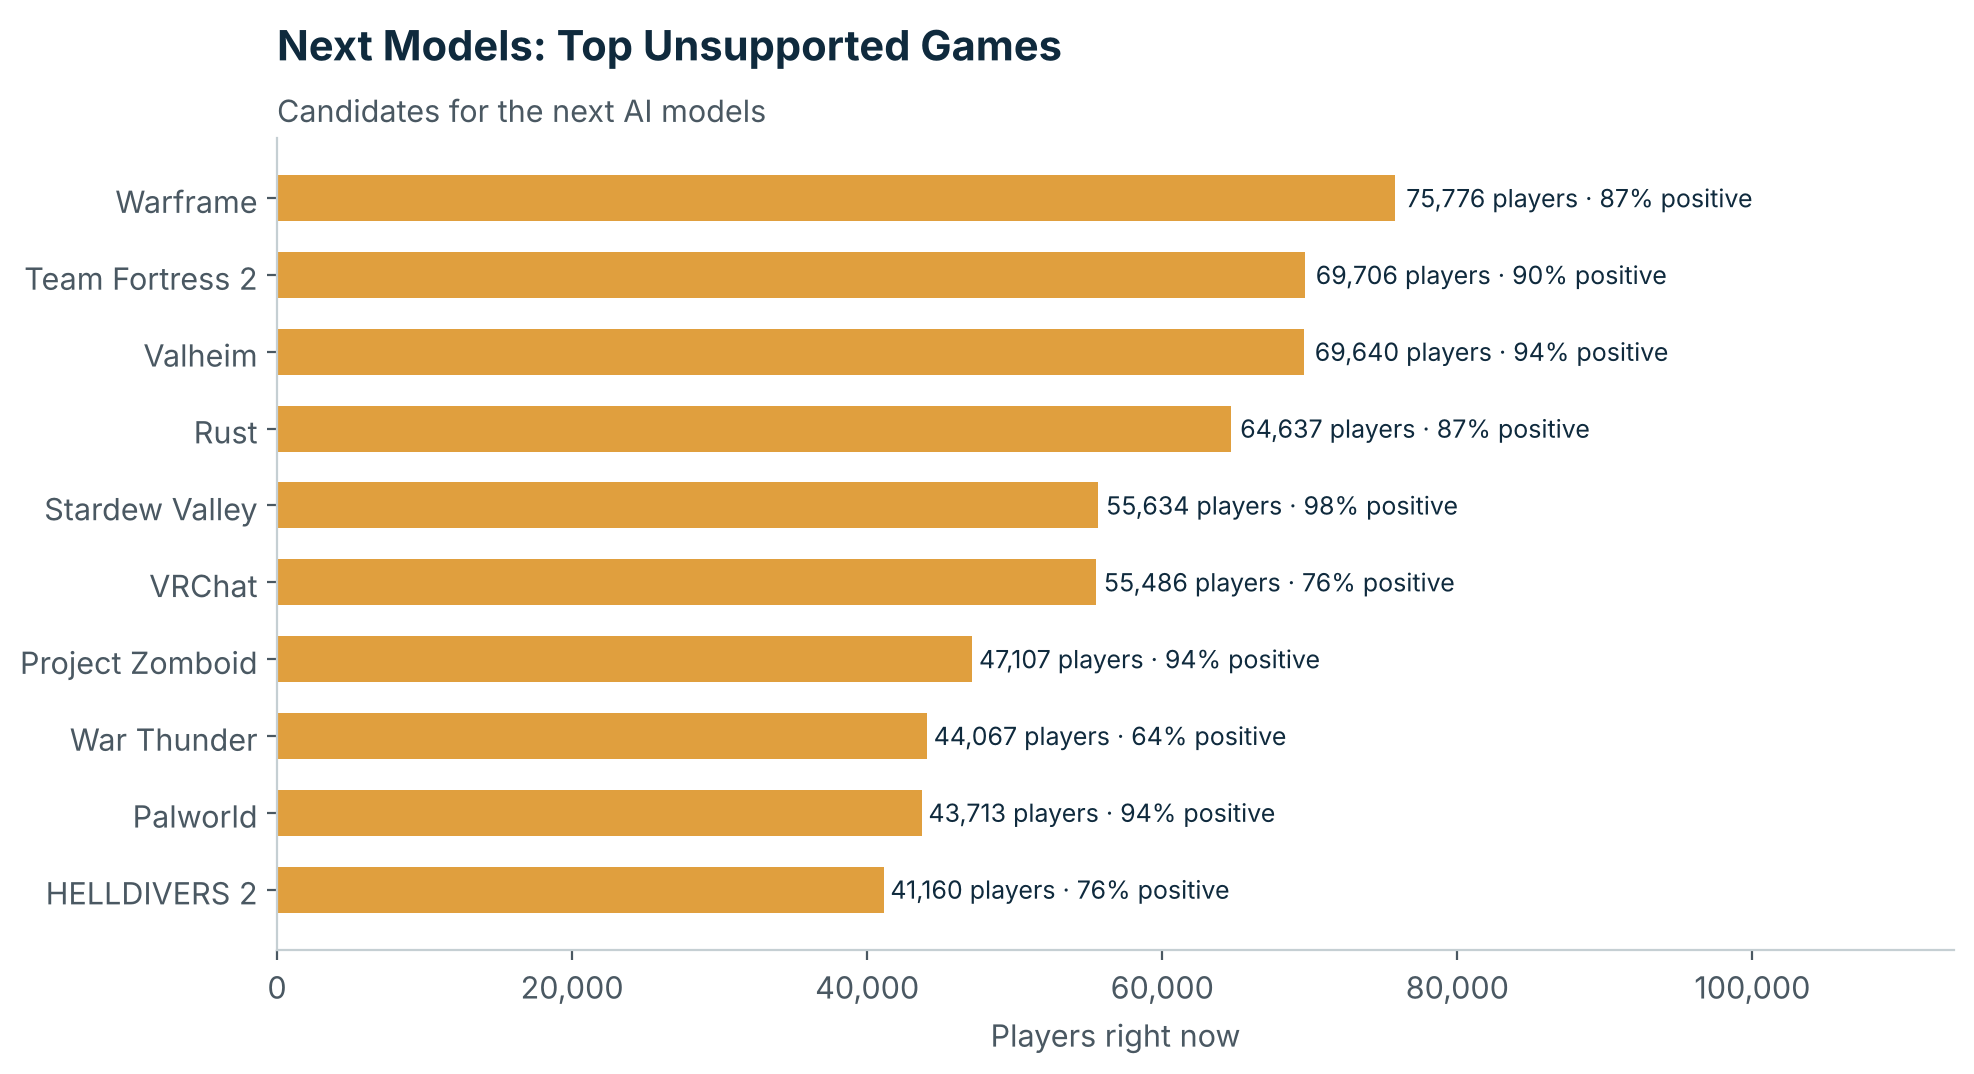

,name,players_now,owners,playtime_2w_hours,positive_reviews_pct
5,Warframe,75776,35000000.0,0.0,87.1
6,Team Fortress 2,69706,75000000.0,0.0,89.9
7,Valheim,69640,15000000.0,0.0,94.3
8,Rust,64637,35000000.0,0.0,87.2
10,Stardew Valley,55634,35000000.0,0.0,98.4
11,VRChat,55486,35000000.0,0.0,75.6
12,Project Zomboid,47107,15000000.0,0.0,94.2
14,War Thunder,44067,35000000.0,0.0,64.0
15,Palworld,43713,75000000.0,0.0,94.1
16,HELLDIVERS 2,41160,35000000.0,0.0,76.2


In [11]:
next_up = games[~games["supported"]].head(10)

plot = next_up.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(plot["name"], plot["players_now"], color=AMBER, height=0.6)
for i, (players, reviews) in enumerate(zip(plot["players_now"], plot["positive_reviews_pct"])):
    ax.text(players * 1.01, i, f"{players:,} players · {reviews:.0f}% positive", va="center", fontsize=9, color=INK)

ax.set_xlim(0, plot["players_now"].max() * 1.5)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Players right now")
ax.set_title("Next Models: Top Unsupported Games", loc="left", fontsize=15, fontweight="bold", color=INK, pad=28)
ax.text(0, 1.02, "Candidates for the next AI models", transform=ax.transAxes, fontsize=11, color=SLATE)
fig.tight_layout()
fig.savefig("task1_next_models.png", dpi=200)
plt.show()

next_up[["name", "players_now", "owners", "playtime_2w_hours", "positive_reviews_pct"]]

In [12]:
print(f"{len(problems)} problems were handled during the run:")
for p in problems:
    print(" -", p)

1 problems were handled during the run:
 - {'appid': 901583}: HTTP 404, skipped


## Summary

*Based on the data collected on 17 October 2026, 05:24 UTC.*

1. **62%** of players in the top 20 Steam games play a game the platform supports. Without Counter-Strike, this drops to **46%**.
2. **Warframe, Team Fortress 2 and Valheim** are the biggest games without a clipping model. They are the best candidates for the next AI models.
3. **Survival games are a gap.** Valheim, Rust, Project Zomboid and Palworld are all popular, and none are supported.
4. **Next step:** run this every day and add Twitch data, to cover games that aren't on Steam.